In [1]:
# Shim: notebook tidak punya __file__.
import os
__file__ = os.path.abspath("jst_2layer_xor.ipynb")

# # Praktikum 1 — JST 2 Layer dari Nol (NumPy) pada XOR
#
# Forward pass + backpropagation manual, aktivasi sigmoid, gradient descent.
# Semua seed dipatok agar reproducible (`np.random.seed(42)`, seed per eksperimen = 0..4).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

HERE = Path(__file__).resolve().parent
OUT = HERE / "output"
OUT.mkdir(exist_ok=True)
np.random.seed(42)  # modul asli TIDAK memakai seed -> hasil tidak reproducible
print("output ->", OUT)

output -> C:\code\pemmes26\js13-artificial-neural-network-ann-dan-evaluasi-classifier\praktikum-1\output


# ## 1. Dataset XOR dan fungsi aktivasi

In [3]:
# Dataset XOR
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])   # 4 sampel, 2 fitur
y = np.array([[0], [1], [1], [0]])               # target biner

input_size, output_size = 2, 1
hidden_size = 2      # konfigurasi awal modul
lr = 0.1
epochs = 10000


def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def sigmoid_derivative(a):      # turunan terhadap z, ditulis sebagai a*(1-a)
    return a * (1 - a)


def relu(z):
    return np.maximum(0.0, z)


def relu_derivative(z):
    return (z > 0).astype(float)


def inisialisasi(hidden=2, seed=None, skala=1.0):
    """Bobot acak ~ N(0,1) seperti modul; seed dipatok supaya bisa diulang."""
    rng = np.random.RandomState(seed)
    return (rng.randn(input_size, hidden), np.zeros((1, hidden)),
            rng.randn(hidden, output_size) * skala, np.zeros((1, output_size)))


def latih(hidden=2, lr=0.1, epochs=10000, seed=None, mode="modul", act="sigmoid"):
    """mode: 'modul' -> W += lr*d (seperti modul), 'gd_mse' -> W -= lr*gradMSE,
    'tanda_terbalik' -> W -= lr*d (yang justru merusak)."""
    W1, b1, W2, b2 = inisialisasi(hidden, seed)
    f, df = (sigmoid, sigmoid_derivative) if act == "sigmoid" else (relu, relu_derivative)
    riwayat = []
    for _ in range(epochs):
        # --- forward pass ---
        z1 = X @ W1 + b1
        a1 = f(z1)
        z2 = a1 @ W2 + b2
        a2 = sigmoid(z2)                  # output selalu sigmoid (probabilitas)
        error = y - a2
        riwayat.append(float(np.mean(error ** 2)))   # loss MSE modul
        # --- backward pass ---
        d2 = error * sigmoid_derivative(a2)
        dW2 = a1.T @ d2
        db2 = d2.sum(axis=0, keepdims=True)
        d1 = (d2 @ W2.T) * (df(z1) if act == "relu" else df(a1))
        dW1 = X.T @ d1
        db1 = d1.sum(axis=0, keepdims=True)
        # --- update ---
        step = {"modul": +lr, "gd_mse": +0.5 * lr, "tanda_terbalik": -lr}[mode]
        W1 += step * dW1; b1 += step * db1
        W2 += step * dW2; b2 += step * db2
    return dict(riwayat=riwayat, a2=a2, params=(W1, b1, W2, b2))

# ## 2. Menjalankan kode modul apa adanya (`W += lr*d`)

In [4]:
hasil_modul = latih(seed=42, mode="modul")
for e in range(0, epochs, 1000):
    print(f"Epoch {e}, Loss: {hasil_modul['riwayat'][e]:.6f}")
print(f"Epoch {epochs-1}, Loss: {hasil_modul['riwayat'][-1]:.6f}")
print("\nPrediksi (seed=42):")
print(np.round(hasil_modul["a2"], 4))
print("Target:", y.ravel())
print("Akurasi biner:", float(np.mean((hasil_modul["a2"] > 0.5) == y)))

Epoch 0, Loss: 0.255830
Epoch 1000, Loss: 0.249406
Epoch 2000, Loss: 0.245445
Epoch 3000, Loss: 0.204707
Epoch 4000, Loss: 0.153204
Epoch 5000, Loss: 0.138691
Epoch 6000, Loss: 0.133594
Epoch 7000, Loss: 0.131151
Epoch 8000, Loss: 0.129749
Epoch 9000, Loss: 0.128849
Epoch 9999, Loss: 0.128227

Prediksi (seed=42):
[[0.053 ]
 [0.4955]
 [0.9509]
 [0.5032]]
Target: [0 1 1 0]
Akurasi biner: 0.5


# ## 3. Uji klaim "bug tanda": apakah `W += lr*d` gradient ascent?
#
# Turunan loss MSE `L = mean((y-a2)^2)` terhadap `W2`:
#
# `dL/dW2 = a1^T @ ( (-2/4) * error * sigmoid'(a2) ) = -0.5 * d_W2`
#
# jadi `d_W2 = a1^T @ (error * sigmoid'(a2))` adalah **negatif gradien**.
# Konsekuensinya `W += lr*d` **sudah** gradient descent (bukan ascent), ekuivalen dengan
# `W -= lr*gradMSE` bila `lr_gd = 2*lr_modul`. Tiga varian diuji di bawah.

loss akhir modul        : 0.1282265715
loss akhir gd_mse lr=.2 : 0.1282265715
selisih maksimum kurva  : 0.00e+00
loss akhir tanda salah  : 0.499817  (prediksi semua ~0.5 -> gagal belajar)


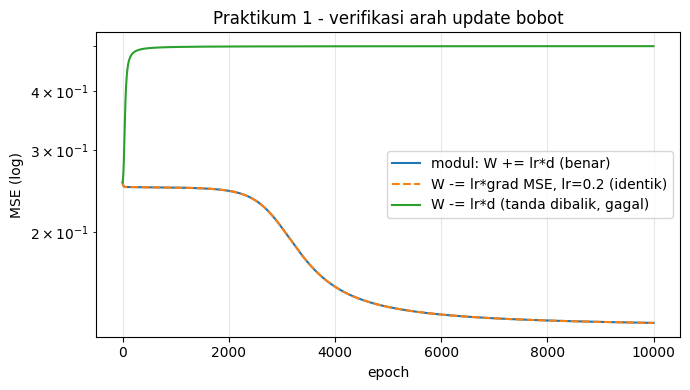

In [5]:
hasil_gd = latih(seed=42, mode="gd_mse", lr=0.2)          # W -= lr*grad(MSE)
hasil_salah = latih(seed=42, mode="tanda_terbalik")       # W -= lr*d (tanda dibalik)

print(f"loss akhir modul        : {hasil_modul['riwayat'][-1]:.10f}")
print(f"loss akhir gd_mse lr=.2 : {hasil_gd['riwayat'][-1]:.10f}")
print(f"selisih maksimum kurva  : {np.max(np.abs(np.array(hasil_modul['riwayat']) - np.array(hasil_gd['riwayat']))):.2e}")
print(f"loss akhir tanda salah  : {hasil_salah['riwayat'][-1]:.6f}  (prediksi semua ~0.5 -> gagal belajar)")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(hasil_modul["riwayat"], label="modul: W += lr*d (benar)")
ax.plot(hasil_gd["riwayat"], "--", label="W -= lr*grad MSE, lr=0.2 (identik)")
ax.plot(hasil_salah["riwayat"], label="W -= lr*d (tanda dibalik, gagal)")
ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("MSE (log)")
ax.set_title("Praktikum 1 - verifikasi arah update bobot")
ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT / "01_arah_update_bobot.png", dpi=120)

# **Kesimpulan:** kode modul tidak salah tanda. Yang benar-benar menjadi masalah adalah
# (a) tidak ada seed sehingga hasil berubah tiap run, dan (b) 2 neuron hidden + sigmoid
# mudah terjebak local minimum. Keduanya dibuktikan pada eksperimen seed di bawah.

# ## 4. Tugas 1 — hidden layer 3 neuron, plus perbandingan ReLU vs Sigmoid

In [6]:
baris = []
for hidden in (2, 3):
    for act in ("sigmoid", "relu"):
        for seed in range(5):
            r = latih(hidden=hidden, act=act, seed=seed, mode="modul")
            baris.append(dict(hidden=hidden, aktifasi=act, seed=seed,
                              loss_awal=r["riwayat"][0], loss_akhir=r["riwayat"][-1],
                              akurasi=float(np.mean((r["a2"] > .5) == y)),
                              konvergen=r["riwayat"][-1] < 0.01))
df = pd.DataFrame(baris)
print(df.to_string(index=False, float_format=lambda v: f"{v:.6f}"))

ringkas = df.groupby(["hidden", "aktifasi"]).agg(
    loss_min=("loss_akhir", "min"), loss_rata2=("loss_akhir", "mean"),
    loss_maks=("loss_akhir", "max"), akurasi_rata2=("akurasi", "mean"),
    konvergen=("konvergen", "sum")).reset_index()
print("\nRekap (5 seed):")
print(ringkas.to_string(index=False, float_format=lambda v: f"{v:.6f}"))
df.to_csv(OUT / "hasil_eksperimen_xor.csv", index=False)

 hidden aktifasi  seed  loss_awal  loss_akhir  akurasi  konvergen
      2  sigmoid     0   0.269637    0.127377 0.500000      False
      2  sigmoid     1   0.256658    0.003462 1.000000       True
      2  sigmoid     2   0.302459    0.002653 1.000000       True
      2  sigmoid     3   0.257780    0.002433 1.000000       True
      2  sigmoid     4   0.322193    0.003003 1.000000       True
      2     relu     0   0.364895    0.250192 0.750000      False
      2     relu     1   0.264596    0.166687 0.750000      False
      2     relu     2   0.295521    0.166693 0.750000      False
      2     relu     3   0.269302    0.166694 0.750000      False
      2     relu     4   0.327455    0.166688 0.750000      False
      3  sigmoid     0   0.257901    0.002664 1.000000       True
      3  sigmoid     1   0.297104    0.002373 1.000000       True
      3  sigmoid     2   0.259695    0.002461 1.000000       True
      3  sigmoid     3   0.259262    0.002105 1.000000       True
      3  s

loss akhir hidden=2: 0.128227 | hidden=3: 0.002297
prediksi hidden=3: [0.0252 0.9526 0.9512 0.0627]


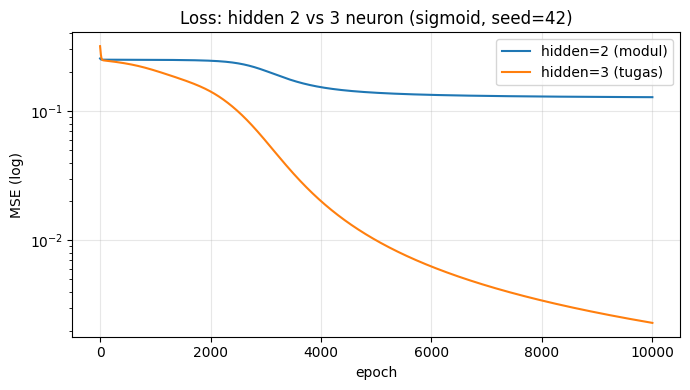

In [7]:
h2 = latih(hidden=2, seed=42); h3 = latih(hidden=3, seed=42)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(h2["riwayat"], label="hidden=2 (modul)")
ax.plot(h3["riwayat"], label="hidden=3 (tugas)")
ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("MSE (log)")
ax.set_title("Loss: hidden 2 vs 3 neuron (sigmoid, seed=42)")
ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT / "02_hidden_2_vs_3.png", dpi=120)
print(f"loss akhir hidden=2: {h2['riwayat'][-1]:.6f} | hidden=3: {h3['riwayat'][-1]:.6f}")
print("prediksi hidden=3:", np.round(h3["a2"].ravel(), 4))

sigmoid loss=0.002297 | relu loss=0.000352
prediksi relu : [0.0297 0.9861 0.9861 0.0116]


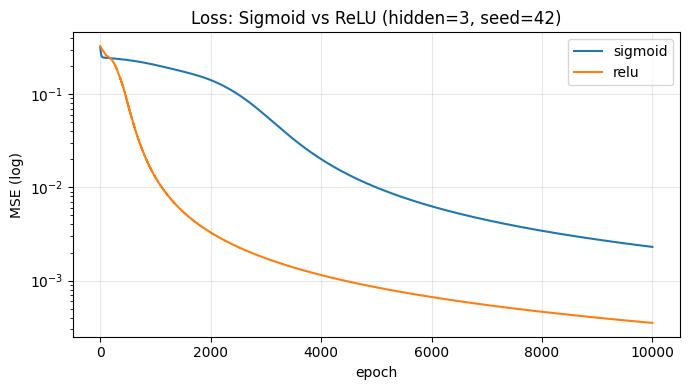

In [8]:
sig3 = latih(hidden=3, act="sigmoid", seed=42)
rel3 = latih(hidden=3, act="relu", seed=42)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sig3["riwayat"], label="sigmoid")
ax.plot(rel3["riwayat"], label="relu")
ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("MSE (log)")
ax.set_title("Loss: Sigmoid vs ReLU (hidden=3, seed=42)")
ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT / "03_sigmoid_vs_relu.png", dpi=120)
print(f"sigmoid loss={sig3['riwayat'][-1]:.6f} | relu loss={rel3['riwayat'][-1]:.6f}")
print("prediksi relu :", np.round(rel3["a2"].ravel(), 4))

# ## 5. Pengaruh seed (modul tanpa seed = tidak reproducible)

loss akhir tiap seed (hidden=2, sigmoid):


  seed=0: 0.127377


  seed=1: 0.003462


  seed=2: 0.002653


  seed=3: 0.002433


  seed=4: 0.003003


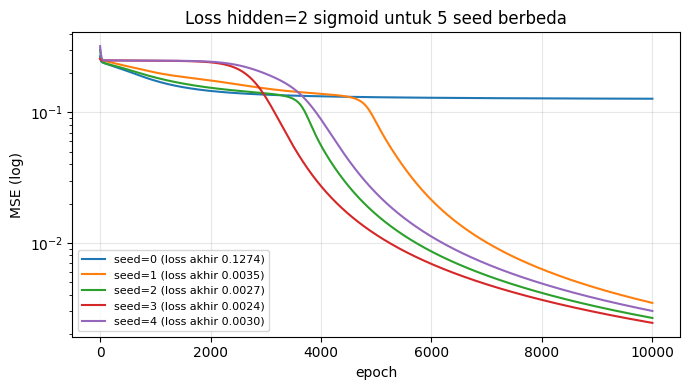

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
for seed in range(5):
    r = latih(hidden=2, act="sigmoid", seed=seed)
    ax.plot(r["riwayat"], label=f"seed={seed} (loss akhir {r['riwayat'][-1]:.4f})")
ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("MSE (log)")
ax.set_title("Loss hidden=2 sigmoid untuk 5 seed berbeda")
ax.legend(fontsize=8); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT / "04_loss_per_seed.png", dpi=120)

print("loss akhir tiap seed (hidden=2, sigmoid):")
for seed in range(5):
    print(f"  seed={seed}: {latih(hidden=2, seed=seed)['riwayat'][-1]:.6f}")